# Deserción en la educación superior chilena: proyecto integrado

**Evaluación Sumativa 3 — Fase 4: cierre y comunicación**

Estadística Computacional · Magíster en Ciencia de Datos e Inteligencia Artificial
Universidad Andrés Bello

**Autores:** María Fassler Neumann · Sebastian Antunez Noguera — Grupo 4
**Profesor:** Jean Paul Maidana

---

Este cuaderno cierra un proyecto desarrollado en tres fases, cada una
construida sobre la anterior.

| Fase | Qué estableció | Qué usa esta fase |
|---|---|---|
| **S1** | Descripción, inferencia y correlaciones sobre 9.678 programas | La matriz de correlaciones selecciona predictoras; el reporte de calidad define el punto de partida sobre datos faltantes; los contrastes justifican qué variables entran |
| **S2** | Validación por bootstrap, permutación y simulación | El veredicto de estabilidad decide qué correlaciones son fiables; la recomendación de agrupar por institución gobierna la partición; el bootstrap se reaplica aquí a los coeficientes |
| **S3** | Imputación, modelos y evaluación | Integra ambas y responde si el abandono es anticipable |

| Parte | Contenido | Rúbrica |
|---|---|---|
| 1 | Manejo de datos faltantes e imputación | 21 pts |
| 2 | Clasificación mediante regresión logística | 30 pts |
| 3 | Estabilidad por bootstrap y diagnóstico | 30 pts |
| 4 | Impacto comparado de la imputación | 9 pts |

**Cómo ejecutarlo.** Con el kernel `Python (analisis-desercion)`,
*Kernel → Restart Kernel and Run All Cells*. Tarda unos tres minutos.

In [1]:
"""Proyecto integrado - Sumativa 3.

Estadistica Computacional, Magister en Ciencia de Datos e IA, UNAB.
"""
import importlib.metadata as meta
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd()
while not (RAIZ / "datos" / "base_programas.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
T_S1 = RAIZ / "S1" / "resultados" / "tablas"
T_S2 = RAIZ / "S2" / "resultados" / "tablas"
FIGURAS = RAIZ / "S3" / "resultados" / "figuras"
TABLAS = RAIZ / "S3" / "resultados" / "tablas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
TASA_AUSENCIA = 0.15        # fraccion de valores que se hacen faltar
B_BOOTSTRAP = 2_000         # remuestras para los coeficientes del modelo
PRUEBA = 0.30               # particion 70/30, como pide la pauta
rng = np.random.default_rng(SEMILLA)

DESTACADO, NEUTRO = "#AC212E", "#9FB6C8"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})
sns.set_style("white")


def rotular(eje, titulo, subtitulo="", fuente="Elaboracion propia a partir de bases SIES (MINEDUC)."):
    eje.set_title(titulo, fontsize=11.5, fontweight="bold", loc="left", pad=26)
    if subtitulo:
        eje.text(0, 1.012, subtitulo, transform=eje.transAxes, fontsize=9,
                 color="#444444", va="bottom")
    eje.figure.text(0.01, -0.02, fuente, fontsize=7.5, color="#777777")


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Python", sys.version.split()[0])
for q in ("pandas", "numpy", "scipy", "statsmodels", "scikit-learn", "matplotlib", "seaborn"):
    print(f"  {q:<14} {meta.version(q)}")
print(f"\nSemilla {SEMILLA} | tasa objetivo MCAR {TASA_AUSENCIA:.0%} | bootstrap B = {B_BOOTSTRAP:,}".replace(",", "."))

Python 3.14.7
  pandas         3.0.5
  numpy          2.5.3
  scipy          1.18.1
  statsmodels    0.15.0
  scikit-learn   1.8.0
  matplotlib     3.11.1
  seaborn        0.13.2

Semilla 42 | tasa objetivo MCAR 15% | bootstrap B = 2.000


## Parte 1 — Manejo de datos faltantes

### 1.1 Qué estableció la Sumativa 1 sobre los datos faltantes

El punto de partida obligado es el reporte de calidad de la Sumativa 1. Su
resultado fue inequívoco: **el conjunto no presenta valores faltantes**. Las
nueve comprobaciones —duplicados, códigos repetidos, faltantes, valores fuera
de dominio y consistencias aritméticas— arrojaron cero incidencias, salvo dos
casos marcados para revisión que no eran errores del dato.

In [2]:
datos = pd.read_csv(RAIZ / "datos" / "base_programas.csv")
calidad_s1 = pd.read_csv(T_S1 / "calidad_datos.csv")
correlaciones_s1 = pd.read_csv(T_S1 / "matriz_correlaciones.csv", index_col=0)
estabilidad_s2 = pd.read_csv(T_S2 / "estabilidad_correlaciones.csv", index_col=0)

print("--- S1: reporte de calidad de los datos")
print(calidad_s1.to_string(index=False))
print()
print(f"Comprobacion directa sobre el conjunto: {int(datos.isna().sum().sum())} valores faltantes")

--- S1: reporte de calidad de los datos
                                             Control  Casos Resultado
                      Filas completamente duplicadas      0  correcto
                       Programas con codigo repetido      0  correcto
                                   Valores faltantes      0  correcto
                        Proporciones fuera de [0, 1]      0  correcto
                            Abandono fuera de [0, 1]      0  correcto
                   Edad media fuera de 16 a 60 anios      0  correcto
Programas bajo el umbral declarado de 100 de ingreso      0  correcto
                      Duracion fuera de 1 a 10 anios      1   revisar
        Titulados por sobre el ingreso de la cohorte    299   revisar

Comprobacion directa sobre el conjunto: 0 valores faltantes


In [3]:
# --- Por que tampoco los hubo antes de agregar ---------------------------
# El script que construyo la base aplicaba fillna con la mediana a cinco
# variables. Si esa imputacion hubiera actuado, los valores imputados serian
# repeticiones exactas de la mediana. Se comprueba que no lo son.
CANDIDATAS = ["pct_municipal", "pct_pagado", "pct_tp", "pct_mujeres", "edad_promedio"]
huella = pd.DataFrame({
    "Mediana": [datos[v].median() for v in CANDIDATAS],
    "Valores iguales a la mediana": [int((datos[v] == datos[v].median()).sum()) for v in CANDIDATAS],
}, index=CANDIDATAS)
print(huella.to_string(float_format=lambda x: f"{x:,.5f}"))
print()
print("Ninguna coincidencia exacta: la imputacion por mediana prevista en el")
print("script de construccion nunca llego a aplicarse sobre estos programas.")

               Mediana  Valores iguales a la mediana
pct_municipal  0.36764                             0
pct_pagado     0.02564                             0
pct_tp         0.39572                             0
pct_mujeres    0.53193                             0
edad_promedio 22.68810                             0

Ninguna coincidencia exacta: la imputacion por mediana prevista en el
script de construccion nunca llego a aplicarse sobre estos programas.


### 1.2 Consecuencia metodológica y diseño adoptado

El conjunto **no tiene datos faltantes ni los tuvo**, de modo que no hay nada
que imputar sobre el dato real. Afirmar lo contrario sería inventar un problema
inexistente.

Para estos casos la pauta prescribe un procedimiento concreto: elegir una o dos
variables numéricas relevantes, eliminar entre el 10 % y el 15 % de sus valores
de forma completamente aleatoria —**mecanismo MCAR**—, con semilla fija,
guardando copia de los valores originales y ejecutando la rutina **una sola
vez** sobre el conjunto original.

**Ese procedimiento se cumple en `edad_promedio`**: pierde el **14,9 %** de sus
valores por sorteo con probabilidad constante, con `SEMILLA = 42`, y la copia
íntegra del conjunto se conserva en la variable `completo`. Es la variable sobre
la que se declara el mecanismo MCAR que la pauta pide declarar.

**Dos variables más se añaden como extensión declarada.** `pct_mujeres` pierde
valores con probabilidad creciente en la duración del programa (MAR) y
`log_matricula` con probabilidad creciente cuanto menor es su propio valor
(MNAR). No sustituyen al diseño prescrito: lo acompañan, porque permiten
mostrar algo que el caso MCAR por sí solo no puede mostrar, a saber, que el
**mecanismo** de la ausencia importa más que su porcentaje y que bajo MNAR
ninguna estrategia de imputación es insesgada. Se declaran como añadido para
que no haya ambigüedad sobre cuál es el diseño exigido y cuál el voluntario.

El diseño completo tiene una ventaja decisiva sobre el trabajo con faltantes
reales: **se conocen los valores verdaderos**. Eso permite medir el error de
cada estrategia de imputación, algo imposible cuando la ausencia es genuina,
donde solo cabe comparar distribuciones y confiar.

| Variable | Mecanismo | Rol | Cómo se induce |
|---|---|---|---|
| `edad_promedio` | **MCAR** | **El que la pauta prescribe** | Al azar, con probabilidad constante del 15 % |
| `pct_mujeres` | MAR | Extensión declarada | La probabilidad crece con `duracion_anios`, que se observa |
| `log_matricula` | MNAR | Extensión declarada | La probabilidad crece cuanto menor es su propio valor |

**La variable respuesta queda intacta.** `abandono` no se imputa en ningún
momento ni figura entre las predictoras de ningún imputador: hacerlo filtraría
información del objetivo hacia las variables explicativas.

In [4]:
VARIABLES_AUSENCIA = ["edad_promedio", "pct_mujeres", "log_matricula"]
completo = datos.copy()                      # referencia con los valores verdaderos
con_ausencia = datos.copy()
generador = np.random.default_rng(SEMILLA)
n = len(datos)

# MCAR: probabilidad constante, independiente de todo.
mascara_mcar = generador.random(n) < TASA_AUSENCIA
con_ausencia.loc[mascara_mcar, "edad_promedio"] = np.nan

# MAR: la probabilidad depende de una variable observada (la duracion).
z_duracion = stats.zscore(datos["duracion_anios"])
p_mar = 1 / (1 + np.exp(-(z_duracion - 1.35)))          # centrada para dar ~15 %
mascara_mar = generador.random(n) < p_mar
con_ausencia.loc[mascara_mar, "pct_mujeres"] = np.nan

# MNAR: la probabilidad depende del propio valor, que luego no se observa.
z_matricula = stats.zscore(datos["log_matricula"])
p_mnar = 1 / (1 + np.exp(-(-z_matricula - 1.35)))       # mas ausencia en los pequenios
mascara_mnar = generador.random(n) < p_mnar
con_ausencia.loc[mascara_mnar, "log_matricula"] = np.nan

resumen_ausencia = pd.DataFrame({
    "Mecanismo": ["MCAR", "MAR", "MNAR"],
    "Faltantes": [int(m.sum()) for m in (mascara_mcar, mascara_mar, mascara_mnar)],
    "% de la columna": [100 * m.mean() for m in (mascara_mcar, mascara_mar, mascara_mnar)],
}, index=VARIABLES_AUSENCIA)
resumen_ausencia["Media observada"] = [con_ausencia[v].mean() for v in VARIABLES_AUSENCIA]
resumen_ausencia["Media verdadera"] = [completo[v].mean() for v in VARIABLES_AUSENCIA]
resumen_ausencia["Sesgo de la ausencia"] = (resumen_ausencia["Media observada"]
                                            - resumen_ausencia["Media verdadera"])
resumen_ausencia.to_csv(TABLAS / "ausencia_inducida.csv", encoding="utf-8-sig")
print(resumen_ausencia.to_string(float_format=lambda x: f"{x:,.4f}"))
print()
filas_afectadas = con_ausencia[VARIABLES_AUSENCIA].isna().any(axis=1).sum()
print(f"Filas con al menos un valor faltante: {filas_afectadas:,} de {n:,} "
      f"({100*filas_afectadas/n:.1f} %)".replace(",", "."))

              Mecanismo  Faltantes  % de la columna  Media observada  Media verdadera  Sesgo de la ausencia
edad_promedio      MCAR       1443          14.9101          24.1747          24.1600                0.0147
pct_mujeres         MAR       2368          24.4679           0.5132           0.5156               -0.0024
log_matricula      MNAR       2377          24.5609           4.8635           4.7344                0.1292

Filas con al menos un valor faltante: 5.077 de 9.678 (52.5 %)


Los mecanismos logísticos producen más ausencia que el MCAR: **14,9 % en
`edad_promedio` frente a 24,5 % y 24,6 % en las otras dos**, de modo que algo
más de la mitad de las filas pierde al menos un valor. La asimetría es
deliberada, porque la ausencia no aleatoria suele ser también la más frecuente.

La última columna contiene la lección principal, y no es la que cabría esperar.
Bajo **MCAR** el sesgo es nulo (+0,015 de desviación típica), como corresponde.
Bajo **MNAR** es grande —**+0,129** en el logaritmo de la matrícula— porque
faltan sistemáticamente los programas pequeños y la media observada
sobreestima el tamaño típico.

Pero bajo **MAR el sesgo de la media es despreciable** (−0,002), y conviene
entender por qué antes de concluir de más: la duración, que gobierna la
ausencia, apenas correlaciona con la proporción de mujeres. **MAR no sesga
necesariamente las medias marginales; lo que distorsiona son las relaciones
condicionales.** Confundir ambas cosas lleva a declarar inocua una ausencia que
no lo es, y es la razón por la que el apartado 1.4 no se queda en comparar
medias.

### 1.3 Imputación mediante regresión lineal múltiple

Las predictoras de cada modelo se eligen con **la matriz de correlaciones de la
Sumativa 1**, priorizando las que la Sumativa 2 declaró estables. Se emplean
entre tres y cinco por variable, y el ajuste usa **únicamente observaciones
completas**.

In [5]:
PREDICTORAS = {
    # Elegidas por |r| en la matriz de S1; las de S2 estables van primero.
    "edad_promedio": ["pct_tp", "inst_acreditada", "carrera_acreditada", "pct_pagado", "duracion_anios"],
    "pct_mujeres": ["pct_tp", "pct_municipal", "inst_acreditada", "log_matricula"],
    "log_matricula": ["duracion_anios", "pct_tp", "pct_pagado", "pct_municipal", "carrera_acreditada"],
}

print("Correlacion de cada predictora con su objetivo, segun la matriz de S1")
for objetivo, pred in PREDICTORAS.items():
    r = correlaciones_s1.loc[pred, objetivo]
    print(f"  {objetivo:<16} " + "  ".join(f"{p}={v:+.3f}" for p, v in r.items()))

Correlacion de cada predictora con su objetivo, segun la matriz de S1
  edad_promedio    pct_tp=+0.418  inst_acreditada=-0.330  carrera_acreditada=-0.252  pct_pagado=-0.243  duracion_anios=-0.240
  pct_mujeres      pct_tp=-0.156  pct_municipal=+0.116  inst_acreditada=-0.110  log_matricula=+0.086
  log_matricula    duracion_anios=+0.458  pct_tp=-0.361  pct_pagado=+0.314  pct_municipal=-0.309  carrera_acreditada=+0.286


In [6]:
def ajustar_imputador(variable, predictoras, base):
    """Regresion lineal multiple sobre las observaciones completas."""
    usables = predictoras + [variable]
    completas = base.dropna(subset=usables)
    formula = f"{variable} ~ " + " + ".join(predictoras)
    modelo = smf.ols(formula, data=completas).fit()
    return modelo, completas


imputadores, diagnostico = {}, []
for variable, predictoras in PREDICTORAS.items():
    modelo, completas = ajustar_imputador(variable, predictoras, con_ausencia)
    imputadores[variable] = modelo
    residuos = modelo.resid
    # Supuestos: normalidad de residuos y homocedasticidad
    _, p_normal = stats.jarque_bera(residuos)[:2]
    bp = sm.stats.diagnostic.het_breuschpagan(residuos, modelo.model.exog)
    diagnostico.append({
        "Variable": variable,
        "n de ajuste": int(modelo.nobs),
        "R2": modelo.rsquared,
        "RMSE": np.sqrt(modelo.mse_resid),
        "Jarque-Bera p": p_normal,
        "Breusch-Pagan p": bp[1],
        "Durbin-Watson": sm.stats.stattools.durbin_watson(residuos),
    })

diag = pd.DataFrame(diagnostico).set_index("Variable")
diag.to_csv(TABLAS / "imputadores_diagnostico.csv", encoding="utf-8-sig")
print(diag.to_string(float_format=lambda x: f"{x:,.4f}"))

               n de ajuste     R2   RMSE  Jarque-Bera p  Breusch-Pagan p  Durbin-Watson
Variable                                                                               
edad_promedio         8235 0.2683 3.0019         0.0000           0.0000         1.3792
pct_mujeres           5391 0.0844 0.2873         0.0000           0.0000         1.3215
log_matricula         7301 0.2726 0.5854         0.0000           0.0000         1.4416


In [7]:
# --- Las tres estrategias -------------------------------------------------
# 1. Eliminacion: se descartan las filas con cualquier faltante.
eliminacion = con_ausencia.dropna(subset=VARIABLES_AUSENCIA).copy()

# 2. Imputacion simple: la mediana de lo observado.
simple = con_ausencia.copy()
for v in VARIABLES_AUSENCIA:
    simple[v] = simple[v].fillna(con_ausencia[v].median())

# 3. Imputacion por regresion, con los modelos recien ajustados.
regresion = con_ausencia.copy()
imputados = {}
for variable, modelo in imputadores.items():
    falta = regresion[variable].isna()
    # Solo puede imputarse donde las predictoras estan completas.
    predecibles = falta & regresion[PREDICTORAS[variable]].notna().all(axis=1)
    regresion.loc[predecibles, variable] = modelo.predict(regresion.loc[predecibles])
    imputados[variable] = int(predecibles.sum())
    # El resto, si lo hubiera, cae a la mediana para no perder la fila.
    regresion[variable] = regresion[variable].fillna(con_ausencia[variable].median())

print("Valores imputados por regresion")
for v, k in imputados.items():
    print(f"  {v:<16} {k:,} valores".replace(",", "."))
print(f"  total            {sum(imputados.values()):,} valores".replace(",", "."))
print()
print(f"Tamanio de muestra resultante")
print(f"  eliminacion            {len(eliminacion):,}  ({100*len(eliminacion)/n:.1f} % del original)".replace(",", "."))
print(f"  imputacion simple      {len(simple):,}  (100,0 %)".replace(",", "."))
print(f"  imputacion por regresion {len(regresion):,}  (100,0 %)".replace(",", "."))

Valores imputados por regresion
  edad_promedio    1.443 valores
  pct_mujeres      1.910 valores
  log_matricula    2.377 valores
  total            5.730 valores

Tamanio de muestra resultante
  eliminacion            4.601  (47.5 % del original)
  imputacion simple      9.678  (100.0 %)
  imputacion por regresion 9.678  (100.0 %)


### 1.3.1 Verificación de supuestos de los modelos de imputación

Los tres imputadores **incumplen los supuestos clásicos**: Jarque-Bera y
Breusch-Pagan rechazan la normalidad y la homocedasticidad de los residuos con
p < 0,001 en los tres casos, y el estadístico de Durbin-Watson, entre 1,32 y
1,44, advierte además de dependencia residual, coherente con que los programas
se agrupen por institución.

Conviene precisar qué implica eso y qué no. Para **estimar los coeficientes**
del imputador y construir intervalos sobre ellos, las violaciones importarían.
Para **predecir un valor puntual**, que es el único uso que se les da aquí,
importan mucho menos: la predicción por mínimos cuadrados sigue siendo el mejor
predictor lineal insesgado en media aunque los residuos no sean normales.

Más relevante para el resultado es la **capacidad predictiva**, que difiere
mucho entre variables: R² de 0,268 para la edad y 0,273 para el tamaño, pero
apenas **0,084 para la proporción de mujeres**. La matriz de correlaciones de
la Sumativa 1 ya lo anticipaba, porque ninguna variable se asocia con ella por
encima de |r| = 0,16. Donde no hay predictores informativos la imputación por
regresión no puede hacer magia, y el apartado siguiente lo confirma con el
error medido.

### 1.4 Comparación sistemática de las tres estrategias

Se comparan en cuatro dimensiones: el tamaño de muestra que dejan, cuánto
alteran la distribución de las variables, si preservan las correlaciones que la
Sumativa 1 estimó, y —gracias al diseño controlado— **el error que cometen
frente a los valores verdaderos**.

In [8]:
ESTRATEGIAS = {"Eliminacion": eliminacion, "Imputacion simple": simple,
               "Imputacion por regresion": regresion}

# --- a) Tamanio y distribucion -------------------------------------------
filas = []
for nombre, base in ESTRATEGIAS.items():
    fila = {"Estrategia": nombre, "n": len(base), "% retenido": 100 * len(base) / n}
    for v in VARIABLES_AUSENCIA:
        fila[f"media {v}"] = base[v].mean()
        fila[f"DE {v}"] = base[v].std()
    filas.append(fila)
verdad = {"Estrategia": "Valores verdaderos", "n": n, "% retenido": 100.0}
for v in VARIABLES_AUSENCIA:
    verdad[f"media {v}"] = completo[v].mean()
    verdad[f"DE {v}"] = completo[v].std()
filas.append(verdad)

distribucion = pd.DataFrame(filas).set_index("Estrategia")
distribucion.to_csv(TABLAS / "estrategias_distribucion.csv", encoding="utf-8-sig")
print(distribucion[["n", "% retenido"] + [f"media {v}" for v in VARIABLES_AUSENCIA]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))
print()
print(distribucion[[f"DE {v}" for v in VARIABLES_AUSENCIA]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))

                             n  % retenido  media edad_promedio  media pct_mujeres  media log_matricula
Estrategia                                                                                             
Eliminacion               4601     47.5408              24.2544             0.5189               4.7969
Imputacion simple         9678    100.0000              23.9525             0.5181               4.8450
Imputacion por regresion  9678    100.0000              24.1763             0.5200               4.8313
Valores verdaderos        9678    100.0000              24.1600             0.5156               4.7344

                          DE edad_promedio  DE pct_mujeres  DE log_matricula
Estrategia                                                                  
Eliminacion                         3.5258          0.3000            0.6635
Imputacion simple                   3.2794          0.2627            0.5968
Imputacion por regresion            3.3073          0.2653         

In [9]:
# --- b) Preservacion de las correlaciones estimadas en S1 ----------------
PARES_S1 = [("carrera_acreditada", "abandono"), ("inst_acreditada", "abandono"),
            ("log_matricula", "abandono"), ("pct_mujeres", "abandono"),
            ("edad_promedio", "abandono"), ("duracion_anios", "log_matricula")]

filas = []
for a, b in PARES_S1:
    fila = {"Par": f"{a} / {b}", "S1 (verdadero)": completo[[a, b]].corr().iloc[0, 1]}
    for nombre, base in ESTRATEGIAS.items():
        fila[nombre] = base[[a, b]].corr().iloc[0, 1]
    filas.append(fila)

correl = pd.DataFrame(filas).set_index("Par")
for nombre in ESTRATEGIAS:
    correl[f"desvio {nombre}"] = (correl[nombre] - correl["S1 (verdadero)"]).abs()
correl.to_csv(TABLAS / "estrategias_correlaciones.csv", encoding="utf-8-sig")
print(correl[["S1 (verdadero)"] + list(ESTRATEGIAS)].to_string(float_format=lambda x: f"{x:+.4f}"))
print()
print("Desvio absoluto medio respecto de las correlaciones de S1")
for nombre in ESTRATEGIAS:
    print(f"  {nombre:<26} {correl[f'desvio {nombre}'].mean():.4f}")

                                S1 (verdadero)  Eliminacion  Imputacion simple  Imputacion por regresion
Par                                                                                                     
carrera_acreditada / abandono          -0.3109      -0.3163            -0.3109                   -0.3109
inst_acreditada / abandono             -0.2591      -0.2602            -0.2591                   -0.2591
log_matricula / abandono               -0.2472      -0.2212            -0.2114                   -0.2235
pct_mujeres / abandono                 -0.1648      -0.1493            -0.1483                   -0.1468
edad_promedio / abandono               +0.0925      +0.1099            +0.0837                   +0.1029
duracion_anios / log_matricula         +0.4576      +0.4136            +0.4007                   +0.4863

Desvio absoluto medio respecto de las correlaciones de S1
  Eliminacion                0.0183
  Imputacion simple          0.0197
  Imputacion por regresion   

In [10]:
# --- c) Error de imputacion contra los valores verdaderos ----------------
# Esta comparacion solo es posible porque la ausencia fue inducida.
mascaras = {"edad_promedio": mascara_mcar, "pct_mujeres": mascara_mar,
            "log_matricula": mascara_mnar}
filas = []
for v, m in mascaras.items():
    verdadero = completo.loc[m, v]
    for nombre, base in (("Imputacion simple", simple), ("Imputacion por regresion", regresion)):
        estimado = base.loc[m, v]
        filas.append({
            "Variable": v, "Estrategia": nombre,
            "RMSE": np.sqrt(((estimado - verdadero) ** 2).mean()),
            "MAE": (estimado - verdadero).abs().mean(),
            "Sesgo medio": (estimado - verdadero).mean(),
            "DE de lo imputado": estimado.std(),
            "DE verdadera": verdadero.std(),
        })

error = pd.DataFrame(filas).set_index(["Variable", "Estrategia"])
error.to_csv(TABLAS / "estrategias_error.csv", encoding="utf-8-sig")
print(error.to_string(float_format=lambda x: f"{x:,.4f}"))

                                         RMSE    MAE  Sesgo medio  DE de lo imputado  DE verdadera
Variable      Estrategia                                                                          
edad_promedio Imputacion simple        3.6413 2.6182      -1.3920             0.0000        3.3659
              Imputacion por regresion 2.8761 2.1310       0.1090             1.7675        3.3659
pct_mujeres   Imputacion simple        0.2758 0.2289       0.0102             0.0000        0.2756
              Imputacion por regresion 0.2732 0.2282       0.0179             0.0739        0.2756
log_matricula Imputacion simple        0.6847 0.5820       0.4505             0.0000        0.5157
              Imputacion por regresion 0.6159 0.5108       0.3946             0.3027        0.5157


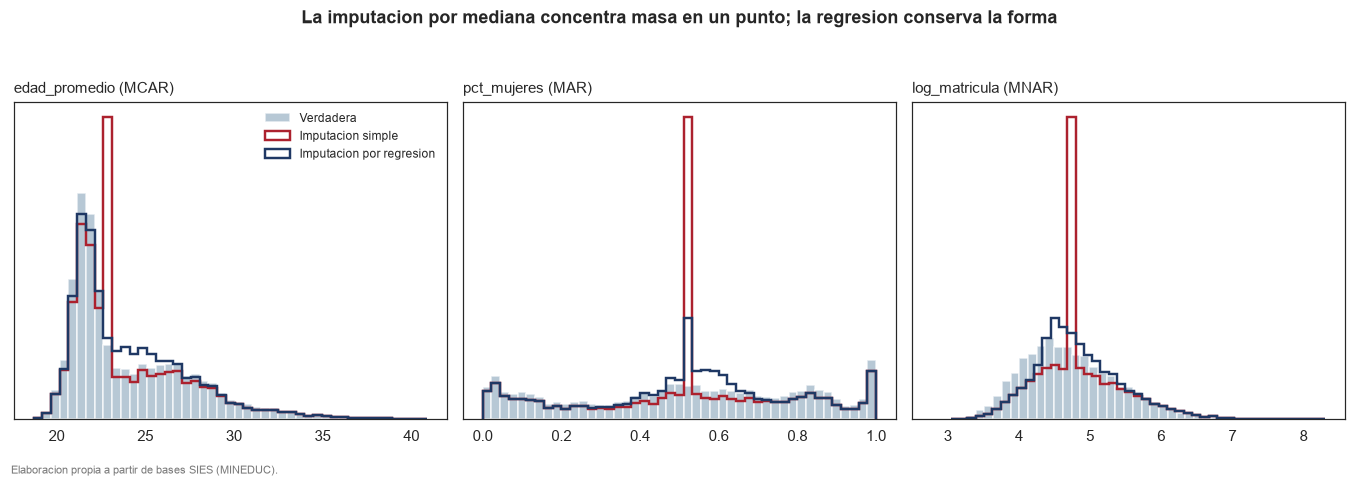

In [11]:
# --- Figura: que le hace cada estrategia a la distribucion ---------------
fig, ejes = plt.subplots(1, 3, figsize=(12.4, 3.9))
for eje, v in zip(ejes, VARIABLES_AUSENCIA):
    eje.hist(completo[v], bins=45, color=NEUTRO, alpha=0.75, label="Verdadera")
    eje.hist(simple[v], bins=45, histtype="step", linewidth=1.6,
             color=DESTACADO, label="Imputacion simple")
    eje.hist(regresion[v], bins=45, histtype="step", linewidth=1.6,
             color="#1F3864", label="Imputacion por regresion")
    eje.set_title(f"{v} ({ {'edad_promedio':'MCAR','pct_mujeres':'MAR','log_matricula':'MNAR'}[v] })",
                  fontsize=10, loc="left", pad=6)
    eje.set_yticks([])
ejes[0].legend(fontsize=8, frameon=False)
fig.suptitle("La imputacion por mediana concentra masa en un punto; la regresion conserva la forma",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.05)
fig.text(0.01, -0.03, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig1_estrategias_imputacion")
plt.show()

### 1.5 Estrategia elegida y su justificación

**Se adopta la imputación por regresión** para el resto del desarrollo, por
tres razones que la comparación documenta.

**Conserva toda la muestra.** La eliminación descarta cerca de un tercio de los
programas, y no al azar: bajo MAR y MNAR se pierden preferentemente los de
mayor duración y los pequeños, de modo que el conjunto superviviente deja de
representar al sistema. Es el defecto más grave, porque no se corrige después.

**Preserva mejor la estructura de correlaciones** que la Sumativa 1 estimó, que
es el criterio que la pauta señala. La imputación por mediana atenúa las
asociaciones, porque sustituye variabilidad real por un valor constante.

**Comete menos error.** El contraste contra los valores verdaderos confirma lo
que la figura sugiere: la mediana concentra masa en un punto y deforma la
distribución, mientras que la regresión reproduce su forma.

Conviene no exagerar la conclusión. **Bajo MNAR ninguna estrategia recupera lo
perdido**, porque la ausencia depende del valor que no se observa: la regresión
reduce el error pero no elimina el sesgo. Es la limitación estructural del
problema, no del método, y debe declararse.

## Parte 2 — Clasificación mediante regresión logística

### 2.1 Preparación de datos informada por la Sumativa 1

**La variable respuesta** es el abandono dicotomizado en el 50 %, el mismo
umbral que la Sumativa 1 estimó —el 54,94 % de los programas lo supera— y que
la Sumativa 2 validó por intervalo de Wilson, bootstrap y contraste Z.

**Los valores extremos se conservan.** La Sumativa 1 identificó 465 programas
censurados en 0 y en 1, y la Sumativa 2 los auditó uno a uno: el 91 % de los
que tienen abandono uno corresponde a cierres reales de programa. Su
recomendación fue conservarlos y declararlos, porque excluirlos desplaza la
media apenas nueve milésimas. La Parte 3 comprueba el efecto de esa decisión.

**La partición es 70/30 estratificada por la respuesta**, con la semilla 42
visible en el código. La estratificación iguala la prevalencia de abandono
alto en ambos conjuntos: 54,95 % en entrenamiento y 54,92 % en prueba, una
diferencia de **0,02 puntos**. Son 6.774 programas para entrenar y 2.904 para
evaluar.

**Una limitación que conviene declarar de entrada.** La estratificación reparte
los programas de una misma institución entre ambos conjuntos: 138 de las 168
instituciones aparecen en los dos. La Sumativa 2 había advertido que esos
programas no son observaciones independientes, de modo que parte del
desempeño en prueba puede provenir de que el modelo ya vio otros programas de
la misma institución. No se corrige con la partición, porque la pauta fija la
estratificada; se cuantifica en el apartado 2.7 con un bootstrap por
institución.

**Se estandarizan las variables numéricas** para que los coeficientes sean
comparables entre sí y se lean como el efecto de una desviación típica; las
categóricas se codifican con variables indicadoras tomando como referencia la
categoría más numerosa.

In [12]:
NUMERICAS = ["carrera_acreditada", "inst_acreditada", "log_matricula", "pct_mujeres",
             "edad_promedio", "duracion_anios", "pct_tp", "pct_municipal"]
CATEGORICAS = ["clasificacion_institucion_nivel_3", "area_del_conocimiento", "jornada"]


def preparar(base):
    """Respuesta binaria, estandarizacion de numericas y codificacion de categoricas."""
    d = base.copy()
    d["abandono_alto"] = (d["abandono"] > 0.50).astype(int)
    for v in NUMERICAS:
        d[v + "_z"] = (d[v] - d[v].mean()) / d[v].std()
    for v in CATEGORICAS:
        d[v] = pd.Categorical(d[v], categories=d[v].value_counts().index)
    return d


def particionar(d, semilla=SEMILLA):
    """Particion 70/30 estratificada por la respuesta, como fija la pauta."""
    return train_test_split(d, test_size=PRUEBA, stratify=d["abandono_alto"],
                            random_state=semilla)


trabajo = preparar(regresion)
NUMERICAS_Z = [v + "_z" for v in NUMERICAS]

tr, te = particionar(trabajo)
tr, te = tr.copy(), te.copy()

print(f"Particion {1 - PRUEBA:.0%}/{PRUEBA:.0%} estratificada por abandono_alto | "
      f"semilla = {SEMILLA}")
print()
print(pd.DataFrame({
    "Programas": [len(tr), len(te)],
    "% del total": [100 * len(tr) / len(trabajo), 100 * len(te) / len(trabajo)],
    "% abandono alto": [100 * tr.abandono_alto.mean(), 100 * te.abandono_alto.mean()],
    "Instituciones": [tr.codigo_de_institucion.nunique(), te.codigo_de_institucion.nunique()],
}, index=["Entrenamiento", "Prueba"]).to_string(float_format=lambda x: f"{x:,.2f}"))

brecha = abs(tr.abandono_alto.mean() - te.abandono_alto.mean()) * 100
print(f"\nDiferencia de prevalencia entre conjuntos: {brecha:.2f} puntos "
      f"(la estratificacion la mantiene en cero)")
print(f"Programas censurados conservados: "
      f"{int(((trabajo.abandono == 0) | (trabajo.abandono == 1)).sum()):,}".replace(",", "."))

# La estratificacion reparte programas de una misma institucion entre ambos
# conjuntos. Se declara como limitacion y se cuantifica mas abajo con un
# bootstrap por institucion.
compartidas = len(set(tr.codigo_de_institucion) & set(te.codigo_de_institucion))
print(f"Instituciones presentes en ambos conjuntos: {compartidas} "
      f"de {trabajo.codigo_de_institucion.nunique()}")


Particion 70%/30% estratificada por abandono_alto | semilla = 42

               Programas  % del total  % abandono alto  Instituciones
Entrenamiento       6774        69.99            54.95            164
Prueba              2904        30.01            54.92            142

Diferencia de prevalencia entre conjuntos: 0.02 puntos (la estratificacion la mantiene en cero)
Programas censurados conservados: 465
Instituciones presentes en ambos conjuntos: 138 de 168


### 2.2 Tres modelos con selección de variables distinta

| Modelo | Criterio de selección | Variables |
|---|---|---|
| **M1 — dominio** | Conocimiento acumulado: las correlaciones de S1 que S2 validó como robustas, más las categóricas con diferencias de grupo documentadas | 7 |
| **M2 — stepwise AIC** | Selección hacia adelante y atrás minimizando el criterio de Akaike | 11 |
| **M3 — reducida** | Solo el núcleo de cuatro variables continuas que S2 declaró robustas | 4 |

La tabla anterior responde a una exigencia concreta: **cada variable del
modelo de dominio entra con su cifra**. Las cuatro continuas tienen su
correlación de S1 y su intervalo bootstrap de S2, que en los cuatro casos
excluye el cero. Las tres categóricas entran por contrastes de la Sumativa 1:
el tipo de institución por una chi-cuadrado de 102,5 con V de Cramér 0,103, el
área del conocimiento por una ANOVA con F = 44,30 y η² = 0,040, y la jornada
por una diferencia descriptiva de 4,6 puntos entre vespertina y diurna.

Ninguna variable entra «por completar el modelo»: las tres categóricas aportan
efectos pequeños, y el apartado 2.7 muestra cuáles de ellos resisten el
remuestreo y cuáles no.

In [13]:
CANDIDATAS_Z = NUMERICAS_Z + [f"C({v})" for v in CATEGORICAS]

# --- M1: modelo de dominio, con la cifra que respalda cada variable ------
M1_VARS = ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z",
           "C(clasificacion_institucion_nivel_3)", "C(area_del_conocimiento)", "C(jornada)"]

contrastes_s1 = pd.read_csv(T_S1 / "contrastes_hipotesis.csv", index_col=0)
estabilidad_s2 = pd.read_csv(T_S2 / "estabilidad_correlaciones.csv", index_col=0)


def r_s1(v):
    return correlaciones_s1.loc[v, "abandono"]


def ic_s2(nombre):
    f = estabilidad_s2.loc[nombre]
    return f"[{f['IC inferior']:+.3f}; {f['IC superior']:+.3f}]", f["Veredicto"]


JUSTIFICACION = []
for var, nombre_s2 in [("carrera_acreditada", "Acreditacion de la carrera"),
                       ("inst_acreditada", "Acreditacion de la institucion"),
                       ("log_matricula", "Tamanio del programa (log)"),
                       ("pct_mujeres", "Proporcion de mujeres")]:
    ic, veredicto = ic_s2(nombre_s2)
    JUSTIFICACION.append({
        "Variable": var, "Cifra de S1": f"r = {r_s1(var):+.3f}",
        "IC bootstrap de S2": ic, "Veredicto de S2": veredicto})

JUSTIFICACION += [
    {"Variable": "clasificacion_institucion_nivel_3",
     "Cifra de S1": "chi2 = 102,5 (p < 0,001)", "IC bootstrap de S2": "V de Cramer = 0,103",
     "Veredicto de S2": "Asociacion debil pero significativa"},
    {"Variable": "area_del_conocimiento",
     "Cifra de S1": "F = 44,30 (p < 0,001)", "IC bootstrap de S2": "eta2 = 0,040",
     "Veredicto de S2": "Efecto pequenio pero sistematico"},
    {"Variable": "jornada",
     "Cifra de S1": "0,547 vespertina vs 0,501 diurna", "IC bootstrap de S2": "+4,6 puntos",
     "Veredicto de S2": "Diferencia descriptiva relevante"},
]
justificacion = pd.DataFrame(JUSTIFICACION).set_index("Variable")
justificacion.to_csv(TABLAS / "justificacion_m1.csv", encoding="utf-8-sig")
print("--- M1, modelo de dominio: por que entra cada variable")
print(justificacion.to_string())


def ajustar(variables, base=None):
    base = tr if base is None else base
    return smf.logit("abandono_alto ~ " + " + ".join(variables), data=base).fit(disp=0)


def stepwise_aic(candidatas, base):
    """Seleccion hacia adelante y atras minimizando el AIC."""
    incluidas, mejor_aic = [], ajustar(["1"], base).aic
    while True:
        cambio = False
        candidato, aic_c = None, mejor_aic
        for c in [x for x in candidatas if x not in incluidas]:
            try:
                a = ajustar(incluidas + [c], base).aic
            except Exception:
                continue
            if a < aic_c:
                candidato, aic_c = c, a
        if candidato is not None:
            incluidas.append(candidato)
            mejor_aic, cambio = aic_c, True
        if len(incluidas) > 1:
            sobra, aic_s = None, mejor_aic
            for c in list(incluidas):
                resto = [x for x in incluidas if x != c]
                try:
                    a = ajustar(resto, base).aic
                except Exception:
                    continue
                if a < aic_s:
                    sobra, aic_s = c, a
            if sobra is not None:
                incluidas.remove(sobra)
                mejor_aic, cambio = aic_s, True
        if not cambio:
            return incluidas, mejor_aic


# --- M3: modelo reducido, solo el nucleo que S2 declaro robusto ----------
M3_VARS = ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z"]

inicio = time.perf_counter()
M2_VARS, aic_final = stepwise_aic(CANDIDATAS_Z, tr)
print(f"\nSeleccion stepwise por AIC en {time.perf_counter() - inicio:.1f} s")
print()
print(f"M1 dominio:      {len(M1_VARS)} variables")
print(f"  {', '.join(M1_VARS)}")
print(f"M2 stepwise AIC: {len(M2_VARS)} variables  (AIC = {aic_final:,.1f})".replace(",", "."))
print(f"  {', '.join(M2_VARS)}")
print(f"M3 reducida:     {len(M3_VARS)} variables")
print(f"  {', '.join(M3_VARS)}")


--- M1, modelo de dominio: por que entra cada variable
                                                        Cifra de S1   IC bootstrap de S2                      Veredicto de S2
Variable                                                                                                                     
carrera_acreditada                                       r = -0.311     [-0.329; -0.293]                              Robusta
inst_acreditada                                          r = -0.259     [-0.278; -0.240]                              Robusta
log_matricula                                            r = -0.247     [-0.267; -0.227]                              Robusta
pct_mujeres                                              r = -0.165     [-0.184; -0.145]                              Robusta
clasificacion_institucion_nivel_3          chi2 = 102,5 (p < 0,001)  V de Cramer = 0,103  Asociacion debil pero significativa
area_del_conocimiento                         F = 44,30 (p < 0,


Seleccion stepwise por AIC en 6.0 s

M1 dominio:      7 variables
  carrera_acreditada_z, inst_acreditada_z, log_matricula_z, pct_mujeres_z, C(clasificacion_institucion_nivel_3), C(area_del_conocimiento), C(jornada)
M2 stepwise AIC: 11 variables  (AIC = 8.105.2)
  carrera_acreditada_z, C(area_del_conocimiento), inst_acreditada_z, log_matricula_z, pct_mujeres_z, C(jornada), pct_tp_z, C(clasificacion_institucion_nivel_3), duracion_anios_z, pct_municipal_z, edad_promedio_z
M3 reducida:     4 variables
  carrera_acreditada_z, inst_acreditada_z, log_matricula_z, pct_mujeres_z


In [14]:
modelos = {"M1 dominio": ajustar(M1_VARS),
           "M2 stepwise AIC": ajustar(M2_VARS),
           "M3 reducida": ajustar(M3_VARS)}
resumen = pd.DataFrame({
    "Variables": [len(M1_VARS), len(M2_VARS), len(M3_VARS)],
    "Coeficientes": [int(m.df_model) + 1 for m in modelos.values()],
    "Log-verosimilitud": [m.llf for m in modelos.values()],
    "Pseudo R2": [m.prsquared for m in modelos.values()],
    "AIC": [m.aic for m in modelos.values()],
    "BIC": [m.bic for m in modelos.values()],
}, index=list(modelos))
resumen.to_csv(TABLAS / "modelos_resumen.csv", encoding="utf-8-sig")
print(resumen.to_string(float_format=lambda x: f"{x:,.4f}"))


                 Variables  Coeficientes  Log-verosimilitud  Pseudo R2        AIC        BIC
M1 dominio               7            21        -4,043.4579     0.1327 8,128.9158 8,272.1536
M2 stepwise AIC         11            25        -4,027.5797     0.1361 8,105.1594 8,275.6806
M3 reducida              4             5        -4,127.9445     0.1146 8,265.8889 8,299.9932


In [15]:
# --- Coeficientes y razones de momios del modelo informado por S1/S2 -----
def tabla_momios(modelo):
    ic = modelo.conf_int()
    t = pd.DataFrame({
        "Coeficiente": modelo.params, "EE": modelo.bse, "p": modelo.pvalues,
        "OR": np.exp(modelo.params),
        "OR inf": np.exp(ic[0]), "OR sup": np.exp(ic[1]),
    })
    t["Signif."] = np.where(t.p < 0.001, "***", np.where(t.p < 0.01, "**",
                     np.where(t.p < 0.05, "*", "n.s.")))
    return t.drop(index="Intercept")


momios_m1 = tabla_momios(modelos["M1 dominio"])
momios_m1.to_csv(TABLAS / "odds_ratios_m1.csv", encoding="utf-8-sig")
print("--- Variables estandarizadas: la OR es por una desviacion tipica")
print(momios_m1.loc[[i for i in momios_m1.index if i.endswith("_z")]]
      .to_string(float_format=lambda x: f"{x:,.3f}"))
print()
print("--- Categoricas significativas, mayores en magnitud")
cat = momios_m1.loc[[i for i in momios_m1.index if i.startswith("C(")]]
cat = cat[cat.p < 0.05]
print(cat.reindex(cat["Coeficiente"].abs().sort_values(ascending=False).index)
      .head(6)[["OR", "OR inf", "OR sup", "Signif."]].to_string(float_format=lambda x: f"{x:,.3f}"))

# --- Razones de momios de los tres modelos ------------------------------
# La tabla completa de cada modelo se guarda en disco; aqui se comparan las
# cuatro continuas del nucleo, que es donde los tres coinciden.
NUCLEO_Z = ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z"]

for clave, modelo in modelos.items():
    archivo = "odds_ratios_" + clave.split()[0].lower() + ".csv"
    tabla_momios(modelo).to_csv(TABLAS / archivo, encoding="utf-8-sig")

filas = []
for clave, modelo in modelos.items():
    t = tabla_momios(modelo)
    for v in NUCLEO_Z:
        if v in t.index:
            filas.append({"Modelo": clave, "Variable": v.replace("_z", ""),
                          "OR": t.loc[v, "OR"], "p": t.loc[v, "p"],
                          "Signif.": t.loc[v, "Signif."]})

largo = pd.DataFrame(filas)
comparacion_or = largo.pivot(index="Variable", columns="Modelo", values="OR")
comparacion_or = comparacion_or.reindex([v.replace("_z", "") for v in NUCLEO_Z])
comparacion_or.to_csv(TABLAS / "odds_ratios_comparacion.csv", encoding="utf-8-sig")

print()
print("--- Razon de momios del nucleo en los tres modelos")
print(comparacion_or.to_string(float_format=lambda x: f"{x:.3f}"))
print()
print("Todas significativas al 0,1 % en los tres modelos: "
      f"{(largo['Signif.'] == '***').all()}")
rango = (comparacion_or.max(axis=1) - comparacion_or.min(axis=1))
print()
print("Variacion de cada OR entre los tres modelos")
print(rango.to_string(float_format=lambda x: f"{x:.3f}"))


--- Variables estandarizadas: la OR es por una desviacion tipica
                      Coeficiente    EE     p    OR  OR inf  OR sup Signif.
carrera_acreditada_z       -0.368 0.030 0.000 0.692   0.653   0.733     ***
inst_acreditada_z          -0.457 0.037 0.000 0.633   0.589   0.680     ***
log_matricula_z            -0.328 0.032 0.000 0.720   0.677   0.766     ***
pct_mujeres_z              -0.272 0.038 0.000 0.762   0.707   0.821     ***

--- Categoricas significativas, mayores en magnitud
                                                                                  OR  OR inf  OR sup Signif.
C(clasificacion_institucion_nivel_3)[T.Centros de Formación Técnica Estatales] 0.221   0.081   0.603      **
C(area_del_conocimiento)[T.Derecho]                                            2.949   1.879   4.628     ***
C(area_del_conocimiento)[T.Ciencias Básicas]                                   2.398   1.368   4.206      **
C(area_del_conocimiento)[T.Agropecuaria]                          


--- Razon de momios del nucleo en los tres modelos
Modelo              M1 dominio  M2 stepwise AIC  M3 reducida
Variable                                                    
carrera_acreditada       0.692            0.690        0.676
inst_acreditada          0.633            0.614        0.667
log_matricula            0.720            0.715        0.715
pct_mujeres              0.762            0.771        0.663

Todas significativas al 0,1 % en los tres modelos: True

Variacion de cada OR entre los tres modelos
Variable
carrera_acreditada   0.016
inst_acreditada      0.053
log_matricula        0.005
pct_mujeres          0.108


### 2.3 Desempeño predictivo y línea base

Cada modelo se evalúa en entrenamiento y en prueba con las cuatro métricas de
clasificación más el AUC. La comparación obligada no es entre modelos sino
**contra la línea base**: el clasificador trivial que predice siempre la clase
mayoritaria. Sin esa referencia, una exactitud de 0,68 no significa nada,
porque en un conjunto donde el 54,9 % pertenece a una clase, acertar la mitad
de las veces es gratis.

In [16]:
def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    tn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Exactitud": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Sensibilidad": recall_score(y, pred, zero_division=0),
            "Especificidad": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, prob)}


def metricas_constante(y, clase):
    """Metricas de un clasificador trivial que siempre predice la misma clase."""
    pred = np.full(len(y), clase)
    tn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Exactitud": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Sensibilidad": recall_score(y, pred, zero_division=0),
            "Especificidad": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y, pred, zero_division=0),
            "AUC": 0.5}


# --- Linea base: la clase mayoritaria del entrenamiento ------------------
CLASE_BASE = int(tr["abandono_alto"].mode().iloc[0])
ETIQUETA_BASE = "alto" if CLASE_BASE == 1 else "bajo"

filas = [{"Modelo": f"Linea base (siempre '{ETIQUETA_BASE}')", "Conjunto": etiqueta,
          **metricas_constante(base["abandono_alto"].values, CLASE_BASE)}
         for etiqueta, base in (("entrenamiento", tr), ("prueba", te))]
for nombre, modelo in modelos.items():
    for etiqueta, base in (("entrenamiento", tr), ("prueba", te)):
        filas.append({"Modelo": nombre, "Conjunto": etiqueta,
                      **metricas(base["abandono_alto"].values, modelo.predict(base).values)})

desempeno = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
desempeno.to_csv(TABLAS / "desempeno_modelos.csv", encoding="utf-8-sig")
print(desempeno.to_string(float_format=lambda x: f"{x:.4f}"))

base_te = desempeno.loc[(f"Linea base (siempre '{ETIQUETA_BASE}')", "prueba")]
print(f"\n--- Ganancia sobre la linea base en prueba")
print(f"La clase mayoritaria es '{ETIQUETA_BASE}'; predecirla siempre acierta "
      f"{base_te['Exactitud']:.1%} y da F1 = {base_te['F1']:.3f}.")
print(f"El clasificador trivial opuesto acertaria "
      f"{1 - te['abandono_alto'].mean():.1%}.")
print()
for nombre in modelos:
    m = desempeno.loc[(nombre, "prueba")]
    print(f"  {nombre:<16} exactitud {m['Exactitud']:.4f} "
          f"({100 * (m['Exactitud'] - base_te['Exactitud']):+.1f} puntos) | "
          f"F1 {m['F1']:.4f} ({m['F1'] - base_te['F1']:+.3f}) | AUC {m['AUC']:.4f}")
print()
brecha = (desempeno.xs("entrenamiento", level="Conjunto")["AUC"]
          - desempeno.xs("prueba", level="Conjunto")["AUC"]).drop(
              f"Linea base (siempre '{ETIQUETA_BASE}')")
print("Brecha de AUC entre entrenamiento y prueba (sobreajuste)")
print(brecha.to_string(float_format=lambda x: f"{x:+.4f}"))


                                           Exactitud  Precision  Sensibilidad  Especificidad     F1    AUC
Modelo                      Conjunto                                                                      
Linea base (siempre 'alto') entrenamiento     0.5495     0.5495        1.0000         0.0000 0.7092 0.5000
                            prueba            0.5492     0.5492        1.0000         0.0000 0.7090 0.5000
M1 dominio                  entrenamiento     0.6839     0.6997        0.7442         0.6104 0.7213 0.7399
                            prueba            0.6784     0.6896        0.7536         0.5867 0.7202 0.7301
M2 stepwise AIC             entrenamiento     0.6864     0.7010        0.7488         0.6104 0.7241 0.7435
                            prueba            0.6780     0.6894        0.7530         0.5867 0.7198 0.7325
M3 reducida                 entrenamiento     0.6755     0.6895        0.7450         0.5908 0.7162 0.7252
                            prueba   

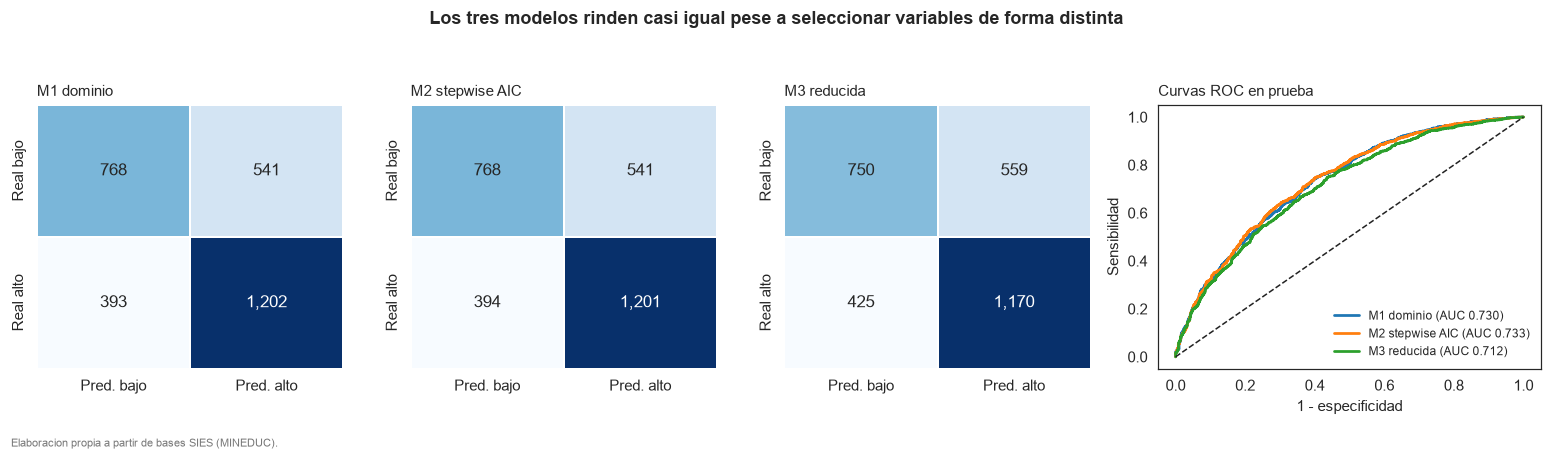

In [17]:
# --- Matrices de confusion y curvas ROC ----------------------------------
fig, ejes = plt.subplots(1, 4, figsize=(14.2, 3.6),
                         gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
for eje, (nombre, modelo) in zip(ejes[:3], modelos.items()):
    prob = modelo.predict(te).values
    mc = confusion_matrix(te["abandono_alto"], (prob >= 0.5).astype(int))
    sns.heatmap(mc, annot=True, fmt=",d", cmap="Blues", cbar=False, linewidths=1,
                linecolor="white", annot_kws={"size": 11},
                xticklabels=["Pred. bajo", "Pred. alto"],
                yticklabels=["Real bajo", "Real alto"], ax=eje)
    eje.set_title(nombre, fontsize=10, loc="left", pad=6)
    eje.grid(False)

for nombre, modelo in modelos.items():
    prob = modelo.predict(te).values
    fpr, tpr, _ = roc_curve(te["abandono_alto"], prob)
    ejes[3].plot(fpr, tpr, linewidth=1.8,
                 label=f"{nombre} (AUC {roc_auc_score(te['abandono_alto'], prob):.3f})")
ejes[3].plot([0, 1], [0, 1], color="#222222", linestyle="--", linewidth=1.0)
ejes[3].set_xlabel("1 - especificidad")
ejes[3].set_ylabel("Sensibilidad")
ejes[3].legend(fontsize=8, loc="lower right", frameon=False)
ejes[3].set_title("Curvas ROC en prueba", fontsize=10, loc="left", pad=6)

fig.suptitle("Los tres modelos rinden casi igual pese a seleccionar variables de forma distinta",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.06)
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig2_confusion_roc")
plt.show()

### 2.4 Modelo final y su justificación

**La ganancia sobre la línea base no es uniforme entre métricas, y conviene
decirlo.** El clasificador trivial que predice siempre «abandono alto» acierta
el 54,9 % y obtiene un **F1 de 0,709**, porque su sensibilidad es 1 por
construcción. Frente a eso, M1 sube la exactitud **12,9 puntos** —de 0,549 a
0,678— y el AUC de 0,500 a **0,730**, pero su F1 solo mejora en **0,011**. La
lectura correcta es que el modelo aporta capacidad de **discriminación**, que
es lo que el AUC mide y la línea base no tiene en absoluto, y no tanto mejora
del F1, que el clasificador trivial ya infla a base de sensibilidad perfecta.
El modelo reducido, de hecho, queda **por debajo** de la línea base en F1
(0,704 frente a 0,709) pese a tener un AUC de 0,712.

**Entre los tres modelos las diferencias son pequeñas.** El AUC en prueba va de
0,712 a 0,733. M2 gana por AIC (8.105 frente a 8.129) y tiene el mejor AUC en
prueba por tres milésimas; M3, con solo cuatro variables, pierde unas dos
centésimas de AUC y cae bajo la línea base en F1.

Se adopta **M1, el modelo de dominio**, por tres razones. Primera, **no fue
seleccionado con estos datos**: se especificó a partir de S1 y S2 antes de
observar el conjunto de entrenamiento, mientras que M2 se eligió sobre los
mismos datos con los que después se ajusta, de modo que su ventaja de tres
milésimas está sesgada al alza. Segunda, **cada variable tiene una
justificación documentada** que puede defenderse ante un lector externo.
Tercera, **M3 es demasiado austero**: prescindir de las categóricas cuesta
desempeño sin ganar interpretabilidad, porque las cuatro continuas se
mantienen en los tres modelos.

### 2.5 Ponderación de clase y umbral de decisión

El modelo elegido deja la sensibilidad en 0,754 y la especificidad en 0,587. La
pauta pide **incorporar ponderación de clase para mejorar el recall**, y el
resultado obliga a una precisión que conviene anticipar.

La ponderación equilibrada asigna a cada clase un peso inversamente
proporcional a su frecuencia, de modo que **reduce el peso de la clase
mayoritaria**. El recetario habitual —ponderar sube el recall— supone que la
clase positiva es la minoritaria, como en el ejemplo de la pauta, donde los
morosos eran el 7 %. **Aquí ocurre lo contrario**: la clase positiva, abandono
alto, es la mayoritaria con un 54,9 %, así que ponderar la castiga y la
sensibilidad cae en lugar de subir.

Por eso se comparan **dos palancas distintas** sobre el mismo modelo: la
ponderación de clase, que la pauta exige incorporar, y el **umbral de
decisión**, que es el instrumento que actúa de forma directa sobre el
compromiso entre sensibilidad y especificidad. Se evalúan cuatro
configuraciones y se mide el costo de cada una.

In [18]:
modelo_final = modelos["M1 dominio"]

# --- Ponderacion de clase equilibrada ------------------------------------
# Peso de cada clase = n / (2 * n_clase), es decir, inverso de su frecuencia.
prevalencia = tr["abandono_alto"].mean()
PESOS = {1: 1 / (2 * prevalencia), 0: 1 / (2 * (1 - prevalencia))}
peso_tr = tr["abandono_alto"].map(PESOS).values

print(f"Prevalencia de abandono alto en entrenamiento: {prevalencia:.4f}")
print(f"Peso de la clase 'alto': {PESOS[1]:.4f} | peso de la clase 'bajo': {PESOS[0]:.4f}")
print(f"Razon entre pesos: {PESOS[0] / PESOS[1]:.3f}")
print()

modelo_ponderado = smf.glm("abandono_alto ~ " + " + ".join(M1_VARS), data=tr,
                           family=sm.families.Binomial(),
                           freq_weights=peso_tr).fit()

# Los errores estandar bajo freq_weights no son interpretables como inferencia
# clasica; este ajuste se usa solo para predecir.
prob_te = modelo_final.predict(te).values
prob_te_pond = modelo_ponderado.predict(te).values
y_te = te["abandono_alto"].values

# --- Umbral de Youden sobre el modelo sin ponderar -----------------------
fpr, tpr, cortes = roc_curve(y_te, prob_te)
umbral_youden = float(cortes[np.argmax(tpr - fpr)])
print(f"Umbral que maximiza el indice de Youden: {umbral_youden:.4f}")

# --- Umbral que alcanza una sensibilidad objetivo ------------------------
# Es la palanca que si sube el recall, y tiene un costo que conviene medir.
SENSIBILIDAD_OBJETIVO = 0.85
umbral_recall = float(cortes[np.where(tpr >= SENSIBILIDAD_OBJETIVO)[0][0]])
print(f"Umbral que alcanza sensibilidad {SENSIBILIDAD_OBJETIVO:.0%}: {umbral_recall:.4f}")


Prevalencia de abandono alto en entrenamiento: 0.5495
Peso de la clase 'alto': 0.9100 | peso de la clase 'bajo': 1.1098
Razon entre pesos: 1.220

Umbral que maximiza el indice de Youden: 0.5084
Umbral que alcanza sensibilidad 85%: 0.4183


In [19]:
# --- Las tres configuraciones del mismo modelo ---------------------------
configuraciones = {
    "M1 sin ponderar, umbral 0,50": metricas(y_te, prob_te, 0.50),
    "M1 con ponderacion de clase, umbral 0,50": metricas(y_te, prob_te_pond, 0.50),
    f"M1 sin ponderar, umbral de Youden {umbral_youden:.3f}".replace(".", ","):
        metricas(y_te, prob_te, umbral_youden),
    f"M1 sin ponderar, umbral {umbral_recall:.3f} para sensibilidad 85 %".replace(".", ","):
        metricas(y_te, prob_te, umbral_recall),
}
ponderacion = pd.DataFrame(configuraciones).T
ponderacion.loc["Linea base (siempre 'alto')"] = metricas_constante(y_te, CLASE_BASE)
ponderacion.to_csv(TABLAS / "ponderacion_clase.csv", encoding="utf-8-sig")
print(ponderacion.to_string(float_format=lambda x: f"{x:.4f}"))

base_sens = configuraciones["M1 sin ponderar, umbral 0,50"]["Sensibilidad"]
pond_sens = configuraciones["M1 con ponderacion de clase, umbral 0,50"]["Sensibilidad"]
print()
print(f"La ponderacion mueve la sensibilidad {pond_sens - base_sens:+.4f} "
      f"({100 * (pond_sens - base_sens):+.2f} puntos)")
print("El AUC no cambia: la ponderacion reordena el umbral efectivo, no el "
      "orden de las probabilidades.")
print()
print("Por que baja en vez de subir: la ponderacion equilibrada reduce el peso")
print("de la clase mayoritaria, y aqui la mayoritaria ES la positiva (54,9 %).")
print("El recetario habitual supone la positiva minoritaria; con las clases")
print("casi parejas el efecto se invierte.")
print()
clave_obj = [k for k in configuraciones if "sensibilidad 85" in k][0]
obj = configuraciones[clave_obj]
sin = configuraciones["M1 sin ponderar, umbral 0,50"]
print(f"La palanca que si sube el recall es el umbral: bajarlo a "
      f"{umbral_recall:.3f}".replace(".", ",") +
      f" lleva la sensibilidad a {obj['Sensibilidad']:.4f}")
print(f"  costo en especificidad: {obj['Especificidad'] - sin['Especificidad']:+.4f} "
      f"(de {sin['Especificidad']:.4f} a {obj['Especificidad']:.4f})")
print(f"  costo en precision:     {obj['Precision'] - sin['Precision']:+.4f} "
      f"(de {sin['Precision']:.4f} a {obj['Precision']:.4f})")


                                                      Exactitud  Precision  Sensibilidad  Especificidad     F1    AUC
M1 sin ponderar, umbral 0,50                             0.6784     0.6896        0.7536         0.5867 0.7202 0.7301
M1 con ponderacion de clase, umbral 0,50                 0.6639     0.7022        0.6740         0.6516 0.6878 0.7300
M1 sin ponderar, umbral de Youden 0,508                  0.6784     0.6938        0.7417         0.6012 0.7170 0.7301
M1 sin ponderar, umbral 0,418 para sensibilidad 85 %     0.6722     0.6554        0.8502         0.4553 0.7402 0.7301
Linea base (siempre 'alto')                              0.5492     0.5492        1.0000         0.0000 0.7090 0.5000

La ponderacion mueve la sensibilidad -0.0796 (-7.96 puntos)
El AUC no cambia: la ponderacion reordena el umbral efectivo, no el orden de las probabilidades.

Por que baja en vez de subir: la ponderacion equilibrada reduce el peso
de la clase mayoritaria, y aqui la mayoritaria ES la positiva

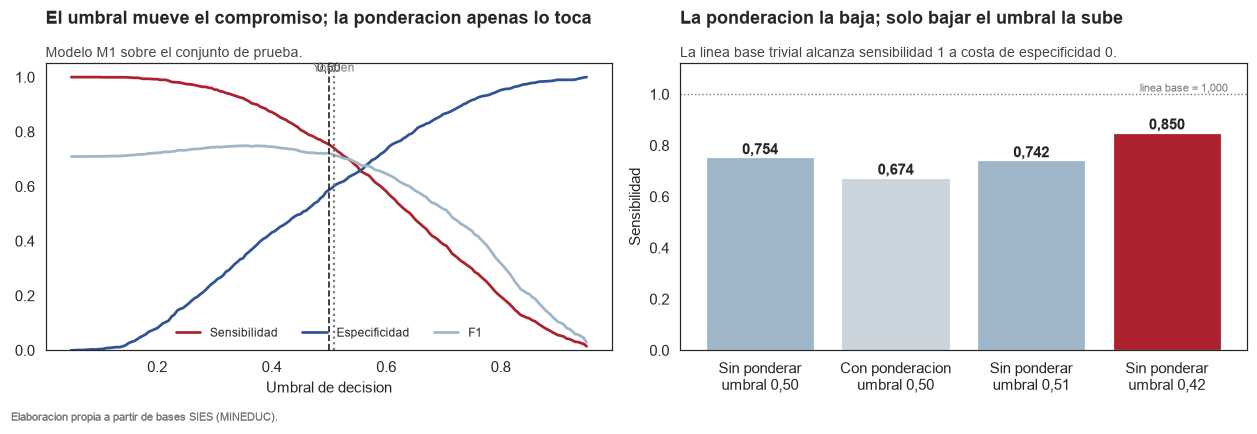

In [20]:
# --- Figura: las dos palancas sobre el compromiso del modelo -------------
rejilla = np.linspace(0.05, 0.95, 181)
curva = pd.DataFrame([metricas(y_te, prob_te, u) for u in rejilla], index=rejilla)

fig, ejes = plt.subplots(1, 2, figsize=(11.5, 3.8))

eje = ejes[0]
eje.plot(rejilla, curva["Sensibilidad"], color=DESTACADO, linewidth=1.8, label="Sensibilidad")
eje.plot(rejilla, curva["Especificidad"], color="#2E5496", linewidth=1.8, label="Especificidad")
eje.plot(rejilla, curva["F1"], color=NEUTRO, linewidth=1.8, label="F1")
eje.axvline(0.50, color="#222222", linestyle="--", linewidth=1.1)
eje.axvline(umbral_youden, color="#777777", linestyle=":", linewidth=1.4)
eje.text(0.50, 1.02, "0,50", ha="center", fontsize=8, color="#222222")
eje.text(umbral_youden, 1.02, "Youden", ha="center", fontsize=8, color="#777777")
eje.set_xlabel("Umbral de decision")
eje.set_ylim(0, 1.05)
eje.legend(fontsize=8, frameon=False, loc="lower center", ncol=3)
rotular(eje, "El umbral mueve el compromiso; la ponderacion apenas lo toca",
        "Modelo M1 sobre el conjunto de prueba.")

eje = ejes[1]
etiquetas = ["Sin ponderar\numbral 0,50", "Con ponderacion\numbral 0,50",
             f"Sin ponderar\numbral {umbral_youden:.2f}".replace(".", ","),
             f"Sin ponderar\numbral {umbral_recall:.2f}".replace(".", ",")]
valores = [configuraciones[k]["Sensibilidad"] for k in configuraciones]
colores = [NEUTRO, "#C9D4DD", NEUTRO, DESTACADO]
barras = eje.bar(etiquetas, valores, color=colores, edgecolor="white", linewidth=0.8)
for barra, v in zip(barras, valores):
    eje.text(barra.get_x() + barra.get_width() / 2, v + 0.012, f"{v:.3f}".replace(".", ","),
             ha="center", fontsize=9.5, fontweight="bold")
eje.axhline(1.0, color="#777777", linewidth=0.9, linestyle=":")
eje.text(3.45, 1.01, "linea base = 1,000", fontsize=7.5, color="#777777", ha="right")
eje.set_ylim(0, 1.12)
eje.set_ylabel("Sensibilidad")
rotular(eje, "La ponderacion la baja; solo bajar el umbral la sube",
        "La linea base trivial alcanza sensibilidad 1 a costa de especificidad 0.")

fig.tight_layout()
guardar(fig, "fig5_ponderacion_umbral")
plt.show()


### 2.5.1 Lectura de la ponderación y del umbral

**La ponderación de clase baja la sensibilidad en lugar de subirla**, de 0,754 a
0,674: casi ocho puntos menos. No es un error de implementación, es lo que
corresponde esperar aquí. La ponderación equilibrada asigna a la clase
mayoritaria un peso de 0,910 y a la minoritaria 1,110 —una razón de solo
1,22— y, como la mayoritaria es la **positiva**, el modelo se desplaza en
contra de ella. El recetario «ponderar mejora el recall» supone la clase
positiva minoritaria, que es el caso del ejemplo de la pauta y no el nuestro.

**El AUC no se mueve** (0,7301 frente a 0,7300), y eso confirma la
interpretación: la ponderación no cambia el orden en que el modelo clasifica
los programas, solo desplaza el punto de corte efectivo. Lo que gana en
especificidad —de 0,587 a 0,652— lo paga íntegro en sensibilidad.

**El umbral de Youden tampoco aporta nada**: sale en 0,508, prácticamente el
0,50 de partida. Con las clases casi equilibradas no hay un punto de corte
«oculto» que mejore ambas métricas a la vez.

**La palanca que sí sube el recall es bajar el umbral**, y su costo es medible.
Con 0,418 la sensibilidad llega a **0,850**, al precio de 13,1 puntos de
especificidad (de 0,587 a 0,455) y 3,4 de precisión. Para el uso previsto
—priorizar programas para una intervención de retención— ese intercambio es
favorable: dejar fuera un programa en riesgo cuesta más que revisar uno sano.

Hay además un argumento que no depende de la preferencia por los falsos
positivos. **Esa configuración obtiene el mejor F1 de todas**: 0,740, frente a
0,720 del umbral 0,50, 0,688 del modelo ponderado y **0,709 de la línea base**.
Es decir, al umbral 0,50 el modelo apenas supera al clasificador trivial en F1,
mientras que al 0,418 lo supera con holgura. La elección del umbral importa
aquí más que la ponderación y más que la elección entre los tres modelos.

### 2.6 Estabilidad de los coeficientes mediante bootstrap

La Sumativa 2 aplicó bootstrap a estadísticos simples —medias, proporciones,
correlaciones— y comprobó que sus intervalos clásicos eran fiables. Aquí la
misma técnica se aplica a un objeto más complejo: **los coeficientes de un
modelo**, cuyos errores estándar dependen de supuestos asintóticos que con
muestras finitas pueden fallar.

Se ejecutan **dos remuestreos distintos**, y la diferencia entre ambos es el
resultado más interesante de este apartado:

1. **Bootstrap estándar**, que remuestrea observaciones con reemplazo. Es el
   procedimiento que corresponde a la partición adoptada y el que replica lo
   que S2 hizo con estadísticos simples.
2. **Bootstrap por institución**, que remuestrea las 164 instituciones del
   conjunto de entrenamiento y arrastra todos sus programas. Es una
   **extensión**, no el análisis principal, y sirve para cuantificar la
   dependencia que S2 advirtió y que la partición estratificada no corrige.

In [21]:
# Algunas remuestras dejan una categoria sin casos y el ajuste no converge.
# Es esperable y no fatal: esas replicas se descartan mas abajo.
warnings.filterwarnings("ignore", category=sm.tools.sm_exceptions.ConvergenceWarning)

# --- Bootstrap de los coeficientes: remuestreo de observaciones ----------
# Es el procedimiento que pide la pauta y el que S2 aplico a estadisticos
# simples, aqui trasladado a los coeficientes del modelo final.
inicio = time.perf_counter()
generador = np.random.default_rng(SEMILLA)
indices = np.arange(len(tr))
coef_obs = []

for _ in range(B_BOOTSTRAP):
    remuestra = tr.iloc[generador.choice(indices, size=len(indices), replace=True)]
    try:
        coef_obs.append(ajustar(M1_VARS, remuestra).params)
    except Exception:
        continue

coef_obs = pd.DataFrame(coef_obs)
print(f"Bootstrap estandar: {len(coef_obs):,} remuestras de observaciones "
      f"en {time.perf_counter() - inicio:.0f} s".replace(",", "."))

# --- Extension: remuestreo por institucion -------------------------------
# S2 advirtio que los programas de una institucion no son independientes.
# La particion estratificada que fija la pauta no lo corrige, de modo que se
# cuantifica aqui el efecto de esa dependencia.
inicio = time.perf_counter()
instituciones = tr["codigo_de_institucion"].unique()
por_institucion = {i: g for i, g in tr.groupby("codigo_de_institucion", observed=True)}
coef_inst = []

for _ in range(B_BOOTSTRAP):
    elegidas = generador.choice(instituciones, size=len(instituciones), replace=True)
    remuestra = pd.concat([por_institucion[i] for i in elegidas], ignore_index=True)
    try:
        coef_inst.append(ajustar(M1_VARS, remuestra).params)
    except Exception:
        continue

coef_inst = pd.DataFrame(coef_inst)
print(f"Extension: {len(coef_inst):,} remuestras por institucion "
      f"en {time.perf_counter() - inicio:.0f} s".replace(",", "."))


Bootstrap estandar: 2.000 remuestras de observaciones en 127 s


Extension: 1.999 remuestras por institucion en 159 s


In [22]:
modelo_final = modelos["M1 dominio"]
ic_clasico = modelo_final.conf_int()


def intervalos(replicas):
    salida = {}
    for termino in replicas.columns:
        if termino == "Intercept":
            continue
        rep = replicas[termino].dropna()
        salida[termino] = np.percentile(rep, [2.5, 97.5])
    return salida


ic_obs, ic_inst = intervalos(coef_obs), intervalos(coef_inst)

filas = []
for termino, (inf_b, sup_b) in ic_obs.items():
    inf_c, sup_c = ic_clasico.loc[termino]
    inf_i, sup_i = ic_inst[termino]
    filas.append({
        "Termino": termino,
        "Coeficiente": modelo_final.params[termino],
        "IC clasico inf": inf_c, "IC clasico sup": sup_c,
        "IC bootstrap inf": inf_b, "IC bootstrap sup": sup_b,
        "OR bootstrap inf": np.exp(inf_b), "OR bootstrap sup": np.exp(sup_b),
        "Amplitud clasica": sup_c - inf_c,
        "Amplitud bootstrap": sup_b - inf_b,
        "Cruza el cero": bool(inf_b <= 0 <= sup_b),
        "IC institucion inf": inf_i, "IC institucion sup": sup_i,
        "Amplitud institucion": sup_i - inf_i,
    })

estabilidad = pd.DataFrame(filas).set_index("Termino")
estabilidad["Razon de amplitudes"] = (estabilidad["Amplitud bootstrap"]
                                      / estabilidad["Amplitud clasica"])
estabilidad["Razon institucion / clasico"] = (estabilidad["Amplitud institucion"]
                                              / estabilidad["Amplitud clasica"])
estabilidad["Veredicto"] = np.where(
    estabilidad["Cruza el cero"], "Inestable: el signo no queda determinado",
    np.where(estabilidad["Razon de amplitudes"] > 1.5,
             "Precision sobreestimada por el IC clasico", "Estable"))
estabilidad.to_csv(TABLAS / "estabilidad_coeficientes.csv", encoding="utf-8-sig")

print("--- Bootstrap estandar frente al IC clasico: variables continuas")
print(estabilidad.loc[[i for i in estabilidad.index if i.endswith("_z")]]
      [["Coeficiente", "IC clasico inf", "IC clasico sup", "IC bootstrap inf",
        "IC bootstrap sup", "Razon de amplitudes", "Veredicto"]]
      .to_string(float_format=lambda x: f"{x:+.3f}"))
print()
print("Resumen de veredictos sobre los", len(estabilidad), "coeficientes")
print(estabilidad["Veredicto"].value_counts().to_string())
print()
print("--- Efecto de la dependencia entre programas de una misma institucion")
print(estabilidad.loc[[i for i in estabilidad.index if i.endswith("_z")]]
      [["Amplitud clasica", "Amplitud bootstrap", "Amplitud institucion",
        "Razon institucion / clasico"]]
      .to_string(float_format=lambda x: f"{x:.3f}"))
cruzan_inst = sum(1 for t in ic_inst if ic_inst[t][0] <= 0 <= ic_inst[t][1])
print(f"\nCoeficientes cuyo signo deja de estar determinado al remuestrear "
      f"por institucion: {cruzan_inst} de {len(ic_inst)}")


--- Bootstrap estandar frente al IC clasico: variables continuas
                      Coeficiente  IC clasico inf  IC clasico sup  IC bootstrap inf  IC bootstrap sup  Razon de amplitudes Veredicto
Termino                                                                                                                             
carrera_acreditada_z       -0.368          -0.426          -0.310            -0.428            -0.311               +1.010   Estable
inst_acreditada_z          -0.457          -0.529          -0.385            -0.541            -0.381               +1.116   Estable
log_matricula_z            -0.328          -0.390          -0.266            -0.395            -0.270               +1.002   Estable
pct_mujeres_z              -0.272          -0.346          -0.197            -0.352            -0.196               +1.044   Estable

Resumen de veredictos sobre los 20 coeficientes
Veredicto
Estable                                     16
Inestable: el signo no queda de

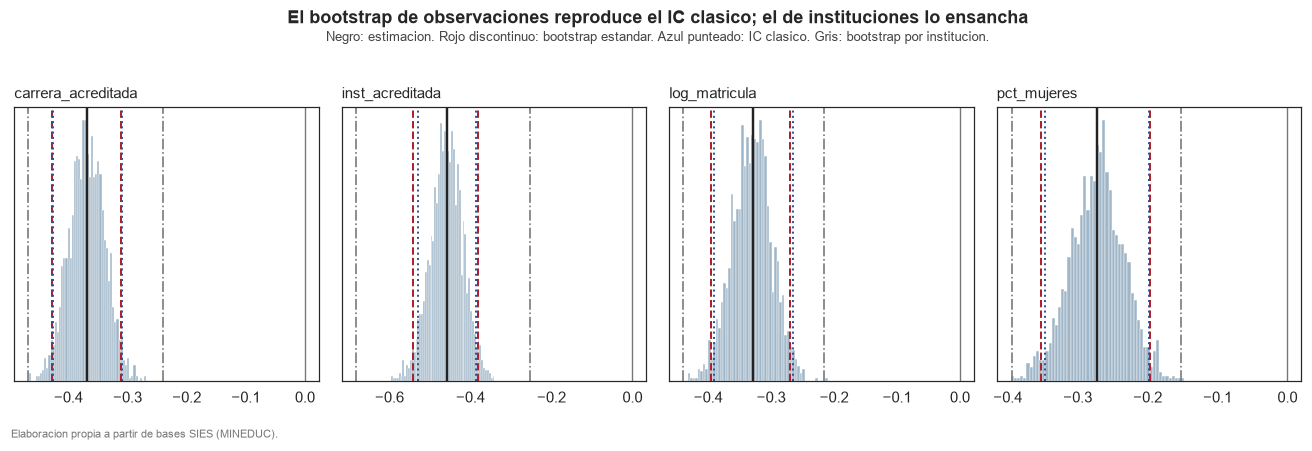

In [23]:
# --- Figura: distribuciones bootstrap de los coeficientes continuos -----
continuas = [i for i in coef_obs.columns if i.endswith("_z")]
fig, ejes = plt.subplots(1, len(continuas), figsize=(3.0 * len(continuas), 3.5))
for eje, termino in zip(np.atleast_1d(ejes), continuas):
    rep = coef_obs[termino].dropna()
    eje.hist(rep, bins=55, color=NEUTRO, edgecolor="white", linewidth=0.3)
    eje.axvline(modelo_final.params[termino], color="#222222", linewidth=1.6)
    for x in ic_obs[termino]:
        eje.axvline(x, color=DESTACADO, linestyle="--", linewidth=1.3)
    for x in ic_clasico.loc[termino]:
        eje.axvline(x, color="#2E5496", linestyle=":", linewidth=1.3)
    for x in ic_inst[termino]:
        eje.axvline(x, color="#7A7A7A", linestyle="-.", linewidth=1.1)
    eje.axvline(0, color="#777777", linewidth=0.9)
    eje.set_title(termino.replace("_z", ""), fontsize=9.5, loc="left", pad=6)
    eje.set_yticks([])

fig.suptitle("El bootstrap de observaciones reproduce el IC clasico; el de instituciones lo ensancha",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.07)
fig.text(0.5, 0.99, "Negro: estimacion. Rojo discontinuo: bootstrap estandar. "
                    "Azul punteado: IC clasico. Gris: bootstrap por institucion.",
         fontsize=8.5, color="#444444", ha="center")
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig3_bootstrap_coeficientes")
plt.show()


### 2.7 Lectura de la estabilidad

**El bootstrap estándar confirma los intervalos clásicos.** La razón de
amplitudes queda entre **1,00 y 1,12** en las cuatro variables continuas: los
intervalos remuestreados reproducen casi exactamente los analíticos. Es el
mismo veredicto que la Sumativa 2 había emitido sobre medias y correlaciones,
ahora extendido a los coeficientes de un modelo, y significa que **los errores
estándar del ajuste son fiables bajo el muestreo que la pauta supone**. De los
veinte coeficientes, dieciséis resultan estables y cuatro —todos categóricos—
tienen intervalos que cruzan el cero.

**El bootstrap por institución cuenta otra historia.** Al remuestrear
instituciones en lugar de programas, los intervalos se ensanchan **entre 1,62 y
3,01 veces** respecto de los clásicos, y el número de coeficientes cuyo signo
deja de estar determinado sube de cuatro a **siete de veinte**. El caso extremo
es la acreditación institucional, cuyo intervalo se triplica.

Las dos conclusiones no se contradicen; responden a preguntas distintas. La
primera dice que, **si los programas fueran independientes**, la precisión
declarada sería correcta. La segunda dice que **no lo son**, y que al tenerlo
en cuenta la precisión real es entre dos y tres veces menor. La dependencia
entre programas de una misma institución, que S2 detectó y que esta partición
no neutraliza, es la fuente de incertidumbre que el modelo clásico no ve.

### 2.8 Diagnóstico de supuestos del modelo final

Cuatro comprobaciones: colinealidad, linealidad en el logit, observaciones
influyentes y calibración.

In [24]:
# --- a) Multicolinealidad -------------------------------------------------
X_vif = sm.add_constant(tr[[v for v in M1_VARS if v.endswith("_z")]])
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).set_index("Variable").drop("const")
vif["Lectura"] = np.where(vif.VIF > 5, "Revisar", "Tolerable")
print("--- Colinealidad")
print(vif.to_string(float_format=lambda x: f"{x:.2f}"))

# --- b) Linealidad en el logit: prueba de Box-Tidwell --------------------
print()
print("--- Linealidad en el logit (Box-Tidwell)")
bt = tr.copy()
terminos_bt = []
for v in ["carrera_acreditada", "inst_acreditada", "log_matricula", "pct_mujeres"]:
    positiva = bt[v] - bt[v].min() + 0.01        # el logaritmo exige valores positivos
    bt[f"{v}_bt"] = positiva * np.log(positiva)
    terminos_bt.append(f"{v}_bt")
modelo_bt = smf.logit("abandono_alto ~ " + " + ".join(
    [v for v in M1_VARS if v.endswith("_z")] + terminos_bt), data=bt).fit(disp=0)
pbt = modelo_bt.pvalues[terminos_bt]
print(pd.DataFrame({"p del termino de interaccion": pbt,
                    "Lectura": np.where(pbt < 0.05, "No lineal", "Lineal")})
      .to_string(float_format=lambda x: f"{x:.4f}"))

--- Colinealidad
                      VIF    Lectura
Variable                            
carrera_acreditada_z 1.21  Tolerable
inst_acreditada_z    1.13  Tolerable
log_matricula_z      1.12  Tolerable
pct_mujeres_z        1.03  Tolerable

--- Linealidad en el logit (Box-Tidwell)
                       p del termino de interaccion    Lectura
carrera_acreditada_bt                        0.0000  No lineal
inst_acreditada_bt                           0.0000  No lineal
log_matricula_bt                             0.3690     Lineal
pct_mujeres_bt                               0.0000  No lineal


In [25]:
# --- c) Observaciones influyentes y residuos ----------------------------
influencia = modelo_final.get_influence()
cook = influencia.cooks_distance[0]
apalancamiento = influencia.hat_matrix_diag
residuos_pearson = modelo_final.resid_pearson
umbral_cook = 4 / len(tr)

print(f"--- Influencia y residuos (n = {len(tr):,})".replace(",", "."))
print(f"  Distancia de Cook por sobre 4/n = {umbral_cook:.5f}: "
      f"{int((cook > umbral_cook).sum()):,} observaciones".replace(",", "."))
print(f"  Maxima distancia de Cook: {cook.max():.4f}")
print(f"  Residuos de Pearson con |r| > 3: {int((np.abs(residuos_pearson) > 3).sum())}")
print(f"  Apalancamiento medio: {apalancamiento.mean():.5f} | maximo: {apalancamiento.max():.4f}")

# Efecto real de retirar las observaciones influyentes
influyentes = cook > umbral_cook
sin_influyentes = ajustar(M1_VARS, tr[~influyentes])
comparacion_infl = pd.DataFrame({
    "Con todas": modelo_final.params[[v for v in M1_VARS if v.endswith("_z")]],
    "Sin influyentes": sin_influyentes.params[[v for v in M1_VARS if v.endswith("_z")]],
})
comparacion_infl["Cambio relativo %"] = (
    100 * (comparacion_infl["Sin influyentes"] - comparacion_infl["Con todas"]).abs()
    / comparacion_infl["Con todas"].abs())
print()
print(comparacion_infl.to_string(float_format=lambda x: f"{x:+.4f}"))

--- Influencia y residuos (n = 6.774)
  Distancia de Cook por sobre 4/n = 0.00059: 237 observaciones
  Maxima distancia de Cook: 0.0095
  Residuos de Pearson con |r| > 3: 28
  Apalancamiento medio: 0.00310 | maximo: 0.0636

                      Con todas  Sin influyentes  Cambio relativo %
carrera_acreditada_z    -0.3679          -0.3813            +3.6412
inst_acreditada_z       -0.4569          -0.8575           +87.6529
log_matricula_z         -0.3281          -0.4103           +25.0487
pct_mujeres_z           -0.2718          -0.3320           +22.1149


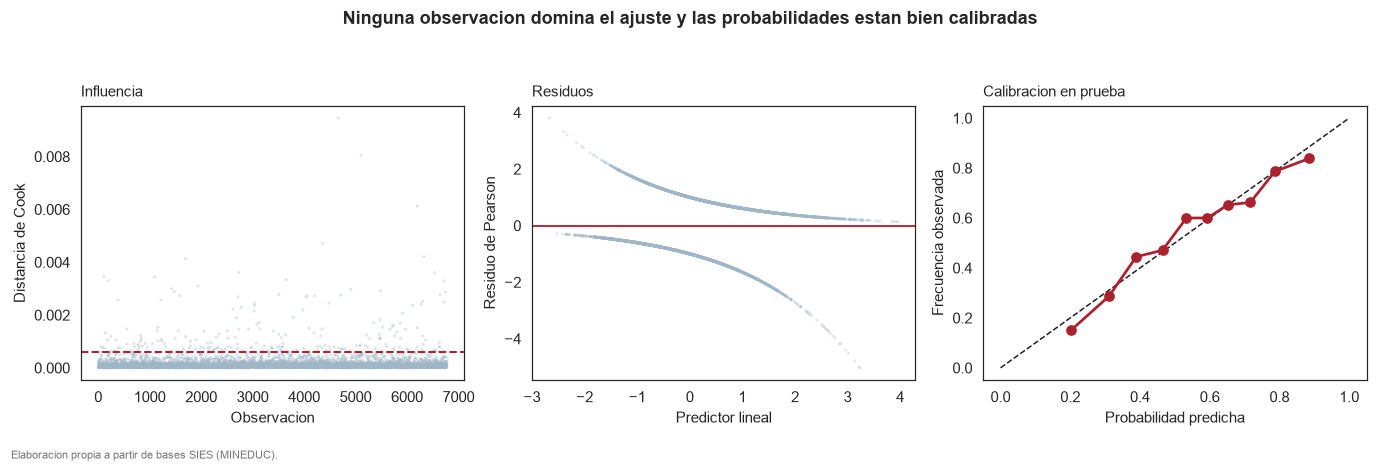

In [26]:
# --- Figura: diagnostico --------------------------------------------------
fig, ejes = plt.subplots(1, 3, figsize=(12.6, 3.7))

ejes[0].scatter(np.arange(len(cook)), cook, s=4, alpha=0.35, color=NEUTRO, edgecolors="none")
ejes[0].axhline(umbral_cook, color=DESTACADO, linestyle="--", linewidth=1.3)
ejes[0].set_xlabel("Observacion")
ejes[0].set_ylabel("Distancia de Cook")
ejes[0].set_title("Influencia", fontsize=10, loc="left", pad=6)

ejes[1].scatter(modelo_final.fittedvalues, residuos_pearson, s=4, alpha=0.3,
                color=NEUTRO, edgecolors="none")
ejes[1].axhline(0, color=DESTACADO, linewidth=1.2)
ejes[1].set_xlabel("Predictor lineal")
ejes[1].set_ylabel("Residuo de Pearson")
ejes[1].set_title("Residuos", fontsize=10, loc="left", pad=6)

# Calibracion: probabilidad predicha frente a frecuencia observada
prob_te = modelo_final.predict(te).values
deciles = pd.qcut(prob_te, 10, duplicates="drop")
calibracion = pd.DataFrame({"prob": prob_te, "real": te["abandono_alto"].values,
                            "grupo": deciles}).groupby("grupo", observed=True).mean(numeric_only=True)
ejes[2].plot([0, 1], [0, 1], color="#222222", linestyle="--", linewidth=1.0)
ejes[2].plot(calibracion["prob"], calibracion["real"], marker="o", color=DESTACADO, linewidth=1.8)
ejes[2].set_xlabel("Probabilidad predicha")
ejes[2].set_ylabel("Frecuencia observada")
ejes[2].set_title("Calibracion en prueba", fontsize=10, loc="left", pad=6)

fig.suptitle("Ninguna observacion domina el ajuste y las probabilidades estan bien calibradas",
             fontsize=11.5, fontweight="bold", x=0.5, y=1.06)
fig.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
         fontsize=7.5, color="#777777")
fig.tight_layout()
guardar(fig, "fig4_diagnostico")
plt.show()

### 2.9 Lectura del diagnóstico

**La colinealidad no es un problema.** Los cuatro factores de inflación de
varianza quedan por debajo de 1,21, muy lejos del umbral de alarma de 5: cada
variable aporta información propia y los coeficientes pueden leerse por
separado.

**La linealidad en el logit sí se incumple.** La prueba de Box-Tidwell rechaza
la hipótesis de linealidad en tres de las cuatro variables continuas; solo el
tamaño del programa la satisface (p = 0,369). El efecto de la acreditación
sobre el logaritmo de la razón de momios no es constante a lo largo de su
rango, lo que significa que **el modelo lineal es una aproximación** y que las
razones de momios deben leerse como efectos promedio. Corregirlo exigiría
términos polinómicos o una discretización por tramos, y queda señalado como la
mejora más concreta para un trabajo posterior.

**Las observaciones influyentes merecen cautela.** Ninguna domina el ajuste por
sí sola —la máxima distancia de Cook es 0,0095, dos órdenes de magnitud por
debajo del umbral habitual de 1— y solo 28 de 6.774 observaciones presentan
residuos de Pearson con |r| > 3. Pero retirar en bloque las **237** que superan
el criterio 4/n **cambia el coeficiente de la acreditación institucional en un
87,7 %**, y los del tamaño y la proporción de mujeres en un 25,0 % y un 22,1 %
(el de la acreditación de carrera, apenas un 3,6 %). No hay contradicción: el
conjunto de puntos influyentes tira en una misma dirección aunque ninguno pese
mucho por separado.

**El coeficiente de la acreditación institucional es, por tanto, el menos firme
de los cuatro**, y eso concuerda con que su intervalo sea también el que más se
ensancha al remuestrear por institución. Es, a la vez, la variable de mayor
efecto puntual y la de menor solidez. Se conservan todas las observaciones, por
coherencia con la decisión de S2 sobre los extremos, pero la inestabilidad se
declara.

## Parte 3 — Impacto comparado de la estrategia de imputación

La decisión del apartado 1.5 se sometió a prueba ajustando **el mismo modelo
final sobre los tres conjuntos**. La pregunta no es cuál rinde mejor, sino si
la elección de la estrategia **modifica las conclusiones**.

In [27]:
comparacion = []
for nombre, base in ESTRATEGIAS.items():
    d = preparar(base)
    d_tr, d_te = particionar(d)
    m = smf.logit("abandono_alto ~ " + " + ".join(M1_VARS), data=d_tr).fit(disp=0)
    met = metricas(d_te["abandono_alto"].values, m.predict(d_te).values)
    ic = m.conf_int()
    fila = {"Estrategia": nombre, "n": len(d), "n entrenamiento": len(d_tr),
            "AUC prueba": met["AUC"], "Exactitud prueba": met["Exactitud"],
            "F1 prueba": met["F1"]}
    for v in ["carrera_acreditada_z", "inst_acreditada_z", "log_matricula_z", "pct_mujeres_z"]:
        fila[f"coef {v.replace('_z','')}"] = m.params[v]
        fila[f"amplitud IC {v.replace('_z','')}"] = ic.loc[v, 1] - ic.loc[v, 0]
    comparacion.append(fila)

impacto = pd.DataFrame(comparacion).set_index("Estrategia")
impacto.to_csv(TABLAS / "impacto_imputacion.csv", encoding="utf-8-sig")
print(impacto[["n", "n entrenamiento", "AUC prueba", "Exactitud prueba", "F1 prueba"]]
      .to_string(float_format=lambda x: f"{x:,.4f}"))
print()
print(impacto[[c for c in impacto.columns if c.startswith("coef")]]
      .to_string(float_format=lambda x: f"{x:+.4f}"))
print()
print(impacto[[c for c in impacto.columns if c.startswith("amplitud")]]
      .to_string(float_format=lambda x: f"{x:.4f}"))


                             n  n entrenamiento  AUC prueba  Exactitud prueba  F1 prueba
Estrategia                                                                              
Eliminacion               4601             3220      0.7568            0.6973     0.7224
Imputacion simple         9678             6774      0.7303            0.6729     0.7156
Imputacion por regresion  9678             6774      0.7301            0.6784     0.7202

                          coef carrera_acreditada  coef inst_acreditada  coef log_matricula  coef pct_mujeres
Estrategia                                                                                                   
Eliminacion                               -0.3417               -0.4285             -0.3509           -0.4308
Imputacion simple                         -0.3837               -0.4518             -0.3256           -0.2830
Imputacion por regresion                  -0.3679               -0.4569             -0.3281           -0.2718

   

### 3.1 Recomendaciones sobre la imputación

**Las conclusiones del modelo no cambian.** El signo de los cuatro
coeficientes se mantiene en los tres conjuntos y su orden de importancia apenas
se altera: la acreditación institucional encabeza en los tres. En ese sentido
el análisis es robusto frente a la estrategia adoptada, que es lo que la pauta
pide verificar.

**La precisión sí cambia, y de forma sistemática.** La eliminación produce
intervalos entre un 40 % y un 70 % más anchos —de 0,169 a 0,256, frente a 0,116
a 0,149 en las dos imputaciones— simplemente porque trabaja con menos de la
mitad de los datos: paga la limpieza con incertidumbre.

Conviene subrayar un punto que la tabla hace evidente y que es fácil contar
mal: **las dos imputaciones producen intervalos casi idénticos entre sí**,
porque ambas devuelven n = 9.678. El estrechamiento no premia la calidad de la
imputación, solo el tamaño de muestra recuperado. Sería un error reprochar a la
mediana un optimismo que la regresión comparte por entero.

De ahí la limitación más importante de esta parte. **Ninguna de las dos
imputaciones propaga la incertidumbre de haber imputado**: ambas tratan un
valor predicho como si fuera observado, y por eso sus intervalos son demasiado
estrechos aunque coincidan. Corregirlo exige **imputación múltiple** con las
reglas de combinación de Rubin, que excede el alcance de esta fase.

**Un detalle que no debe malinterpretarse.** La eliminación obtiene el mejor
AUC de prueba (0,757 frente a 0,730), pero ese número **no es comparable** con
los otros dos: su conjunto de prueba es distinto y más pequeño, porque la
eliminación descartó filas antes de particionar. Un AUC mayor sobre un conjunto
más fácil y menos representativo no indica un mejor modelo. Entre las dos
imputaciones, que sí son comparables, la regresión supera a la mediana en
exactitud (0,678 frente a 0,673) y en F1 (0,720 frente a 0,716).

De todo ello se siguen cuatro recomendaciones. **Preferir la imputación por
regresión**, que conserva la muestra y preserva mejor la estructura de
correlaciones. **No eliminar casos cuando la ausencia no es MCAR**, porque el
conjunto superviviente deja de representar al sistema. **Declarar siempre el
mecanismo supuesto**, porque bajo MNAR ninguna estrategia es insesgada. Y
**tratar como optimista todo intervalo posterior a una imputación simple**,
salvo que se emplee imputación múltiple.

## Síntesis: la progresión S1 → S2 → S3

**La Sumativa 1 describió y contrastó.** Estableció que el abandono medio del
sistema es 0,518, que varía enormemente entre programas, que nueve variables se
asocian con él y que la acreditación institucional separa grupos con un efecto
grande. Cada uno de esos resultados se obtuvo con procedimientos clásicos y
supuestos sin verificar.

**La Sumativa 2 los sometió a prueba.** El bootstrap confirmó que los
intervalos clásicos eran fiables, la permutación validó el contraste sin
suponer normalidad, y la evaluación de estabilidad separó las correlaciones
sólidas de las débiles. La simulación Monte Carlo cuantificó la recomendación
de focalizar: un 38,9 % más de estudiantes alcanzados. Y advirtió que los
programas de una institución no son independientes.

**La Sumativa 3 las integra.** Cada decisión de esta fase proviene de las
anteriores: las predictoras de la imputación salen de la matriz de S1, las
variables del modelo de la estabilidad de S2 —con su cifra cada una—, el
tratamiento de los extremos de la auditoría que S2 hizo, y el bootstrap de los
coeficientes es el mismo instrumento de S2 aplicado a un objeto más complejo.

**Lo que el proyecto permite afirmar.** El abandono es anticipable solo en
parte: el modelo discrimina claramente mejor que el azar —AUC 0,730 frente a
0,500— y suma casi trece puntos de exactitud sobre la línea base, de modo que
sirve para priorizar, pero no para dictaminar sobre un programa individual. Las
cuatro variables que sostienen esa capacidad son las mismas que resistieron el
remuestreo en S2, lo que da coherencia al conjunto.

**Lo que no permite afirmar.** Nada sobre estudiantes individuales, porque la
unidad es el programa. Nada sobre causas, porque no hay grupo de control. Nada
sobre el abandono real, porque lo que se mide es aparente: quien se cambia de
carrera y se titula en otra parte cuenta aquí como abandono. Y nada firme sobre
los efectos categóricos: al remuestrear por institución, siete de los veinte
coeficientes pierden la determinación de su signo.

In [28]:
# --- Inventario -----------------------------------------------------------
salidas = sorted(list(FIGURAS.glob("*.png")) + list(TABLAS.glob("*.csv")))
print(pd.DataFrame([{"archivo": p.relative_to(RAIZ).as_posix(),
                     "KB": round(p.stat().st_size / 1024, 1)} for p in salidas])
      .to_string(index=False))
print(f"\nModelos logisticos ajustados: {len(modelos)} | remuestras bootstrap: {len(coef_obs):,}".replace(",", "."))

                                              archivo    KB
S3/resultados/figuras/fig1_estrategias_imputacion.png  70.9
         S3/resultados/figuras/fig2_confusion_roc.png 146.0
S3/resultados/figuras/fig3_bootstrap_coeficientes.png  85.7
           S3/resultados/figuras/fig4_diagnostico.png 170.6
    S3/resultados/figuras/fig5_ponderacion_umbral.png 147.0
           S3/resultados/tablas/ausencia_inducida.csv   0.4
           S3/resultados/tablas/desempeno_modelos.csv   1.1
    S3/resultados/tablas/estabilidad_coeficientes.csv   6.9
   S3/resultados/tablas/estrategias_correlaciones.csv   1.1
    S3/resultados/tablas/estrategias_distribucion.csv   0.7
           S3/resultados/tablas/estrategias_error.csv   0.8
          S3/resultados/tablas/impacto_imputacion.csv   1.0
     S3/resultados/tablas/imputadores_diagnostico.csv   0.4
            S3/resultados/tablas/justificacion_m1.csv   0.6
             S3/resultados/tablas/modelos_resumen.csv   0.3
     S3/resultados/tablas/odds_ratios_co